# NetForensics AI: Visualization and Final Analysis

## Phase 5: Results Visualization and Project Analysis

This notebook presents the final analysis and visualizations for the NetForensics AI project.

The visualizations help understand:

- Distribution of network protocols.
- Distribution of OSI layers.
- Severity levels of network faults.
- AI confidence levels.
- Human review requirements.
- Similarity score distribution.
- Overall performance of the NetForensics AI system.

These results provide insights into the dataset and the performance of the AI-assisted network troubleshooting approach.

## 1. Import Required Libraries

The following libraries are used for data analysis and visualization.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load Final Human Review Results

The final dataset generated during the Human Review and Responsible AI phase is loaded for visualization and analysis.

In [3]:
df = pd.read_csv("human_review_results.csv")

print("Final results loaded successfully.")
print("Total number of cases:", len(df))

Final results loaded successfully.
Total number of cases: 100


## 3. Display Dataset Overview

This step displays the dataset structure and confirms the availability of the columns required for visualization.

In [ ]:
print("Dataset Shape:", df.shape)

print("\nAvailable Columns:")
print(df.columns.tolist())

## 4. Network Protocol Distribution

This visualization shows the number of fault cases associated with each network protocol or technology.

It helps identify which protocols are most represented in the NetForensics AI dataset.

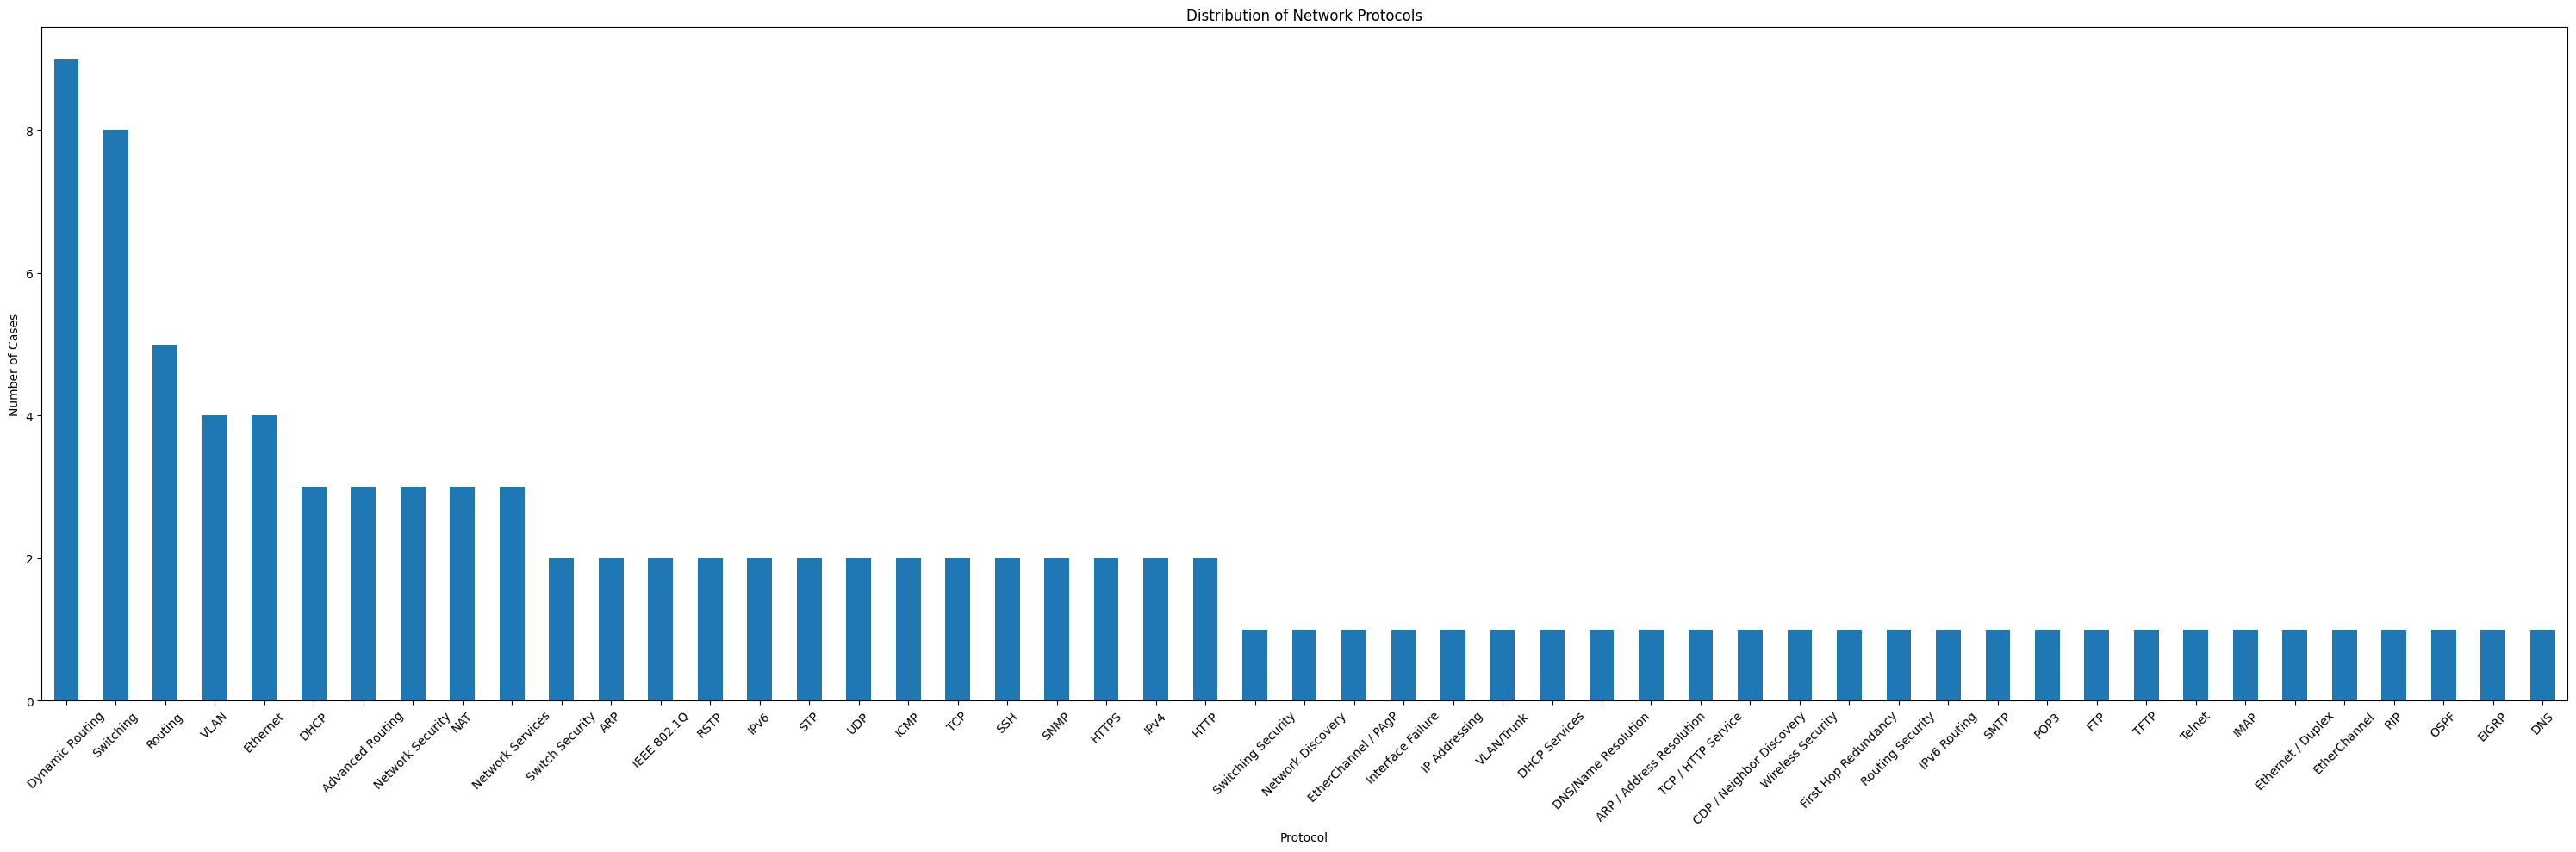

In [12]:
protocol_count = df["Category"].value_counts()

plt.figure(figsize=(30, 10))

protocol_count.plot(kind="bar")

plt.title("Distribution of Network Protocols")
plt.xlabel("Protocol")
plt.ylabel("Number of Cases")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## 5. OSI Layer Distribution

This visualization shows how the network fault cases are distributed across different OSI layers.

It helps understand which layers contain the highest number of troubleshooting cases.

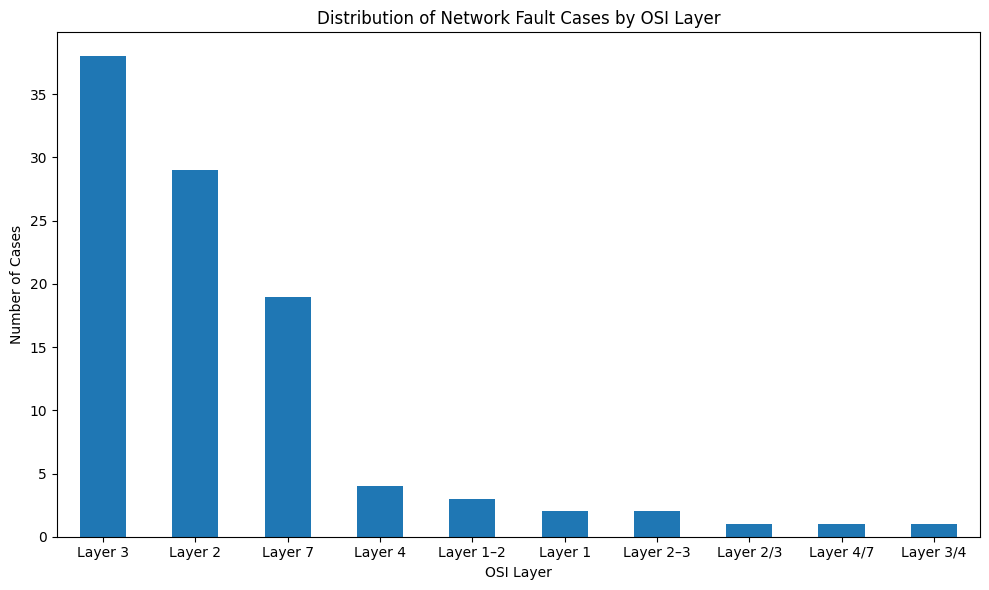

In [13]:
osi_count = df["OSI_Layer"].value_counts()

plt.figure(figsize=(10, 6))

osi_count.plot(kind="bar")

plt.title("Distribution of Network Fault Cases by OSI Layer")
plt.xlabel("OSI Layer")
plt.ylabel("Number of Cases")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

## 6. Network Fault Severity Distribution

This visualization shows the distribution of network fault cases based on severity levels.

Severity helps prioritize troubleshooting and incident response.

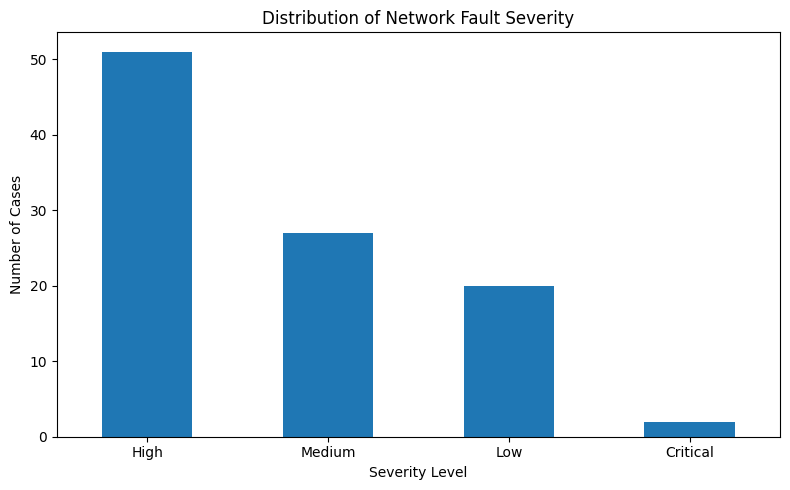

In [14]:
severity_count = df["Severity"].value_counts()

plt.figure(figsize=(8, 5))

severity_count.plot(kind="bar")

plt.title("Distribution of Network Fault Severity")
plt.xlabel("Severity Level")
plt.ylabel("Number of Cases")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

## 7. AI-Assisted Diagnosis Confidence Distribution

This visualization shows the number of cases categorized as High, Medium, or Low confidence by the similarity-based diagnosis system.

The confidence level is based on the similarity score between the current case and historical network fault cases.

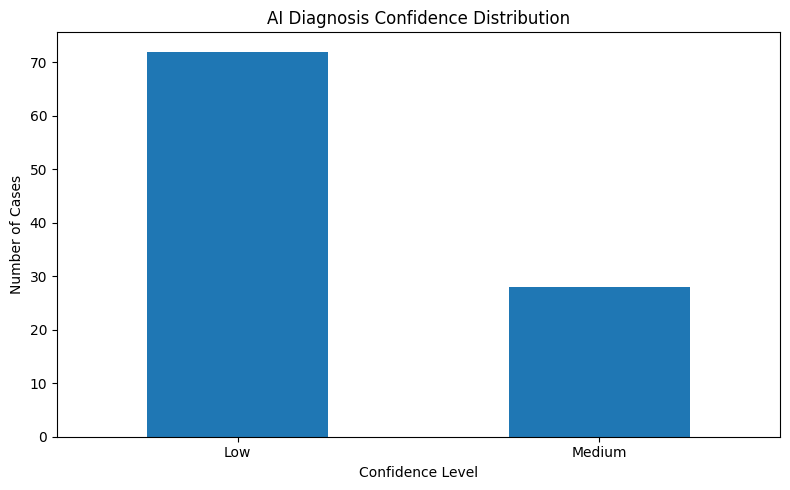

In [15]:
confidence_count = df["AI_Confidence"].value_counts()

plt.figure(figsize=(8, 5))

confidence_count.plot(kind="bar")

plt.title("AI Diagnosis Confidence Distribution")
plt.xlabel("Confidence Level")
plt.ylabel("Number of Cases")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

## 8. Human Review Priority Distribution

This visualization shows the priority assigned to human review based on the confidence level of the AI-assisted diagnosis.

Cases with low AI confidence receive higher human review priority.

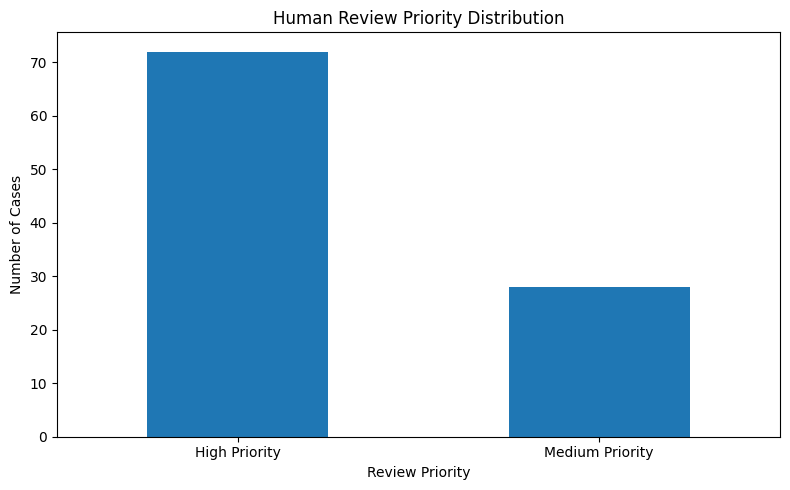

In [17]:
review_priority_count = df["Human_Review_Priority"].value_counts()

plt.figure(figsize=(8, 5))

review_priority_count.plot(kind="bar")

plt.title("Human Review Priority Distribution")
plt.xlabel("Review Priority")
plt.ylabel("Number of Cases")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

## 9. Final Review Recommendation Distribution

This visualization shows the final actions recommended by the NetForensics AI system.

The recommendations determine whether an automated diagnosis can be accepted or requires human verification.

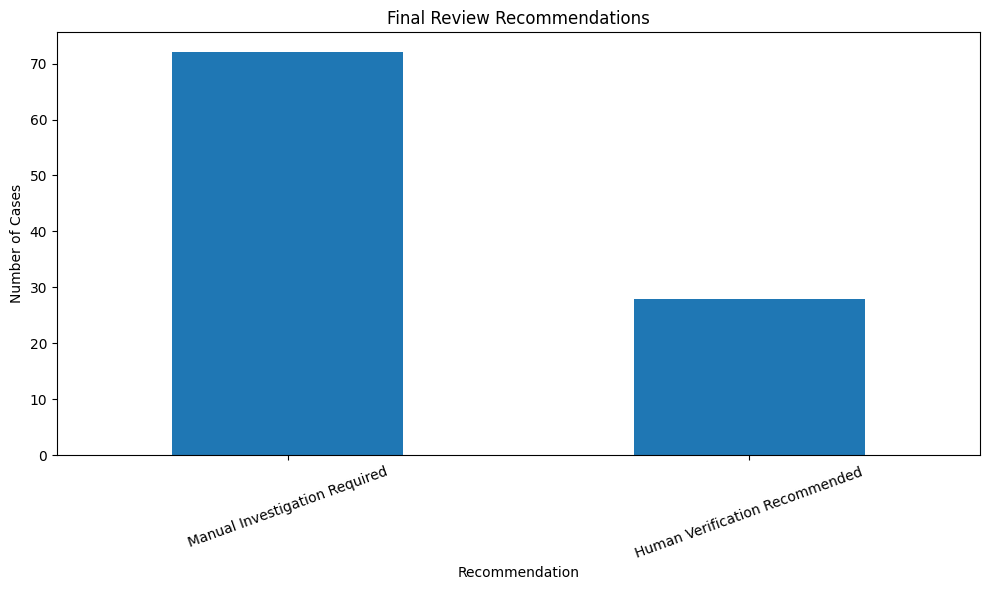

In [18]:
recommendation_count = df[
    "Final_Review_Recommendation"
].value_counts()

plt.figure(figsize=(10, 6))

recommendation_count.plot(kind="bar")

plt.title("Final Review Recommendations")
plt.xlabel("Recommendation")
plt.ylabel("Number of Cases")

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

## 10. AI Similarity Score Distribution

This visualization shows the distribution of similarity scores generated by the TF-IDF and cosine similarity approach.

Higher similarity scores indicate that a network case has a stronger match with an existing historical troubleshooting case.

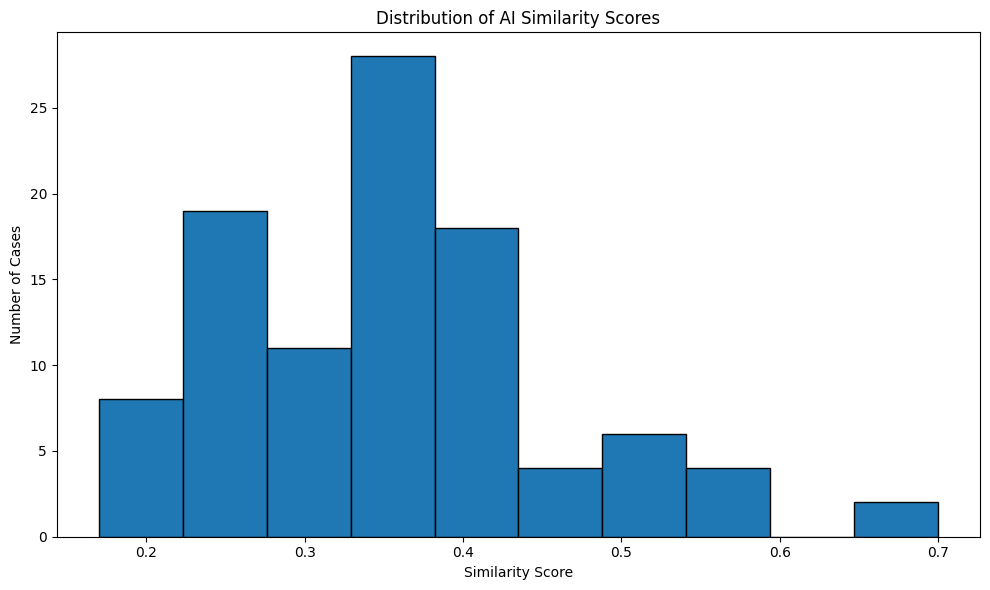

In [19]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["AI_Similarity_Score"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of AI Similarity Scores")
plt.xlabel("Similarity Score")
plt.ylabel("Number of Cases")

plt.tight_layout()

plt.show()

## 11. Evaluation of Similarity-Based Case Retrieval

The NetForensics AI system uses similarity-based retrieval rather than direct classification.

Each network fault case is compared with other historical cases, and the most similar case is retrieved.

Because individual fault descriptions may be unique, exact text matching of fault descriptions can be overly strict.

Therefore, the retrieval system is also evaluated by checking whether the retrieved similar case belongs to the same network protocol category as the original case.

In [27]:
# Get protocol of the retrieved similar case

similar_protocols = []

for case_id in df["AI_Similar_Case_ID"]:

    similar_row = df[df["Case_ID"] == case_id]

    if not similar_row.empty:
        protocol = similar_row.iloc[0]["Category"]
    else:
        protocol = None

    similar_protocols.append(protocol)

df["AI_Similar_Protocol"] = similar_protocols

print("Similar case protocols added successfully.")

Similar case protocols added successfully.


In [29]:
df["Protocol_Match"] = (
    df["Category"].astype(str).str.lower().str.strip()
    ==
    df["AI_Similar_Protocol"].astype(str).str.lower().str.strip()
)

correct_retrievals = df["Protocol_Match"].sum()
total_cases = len(df)

retrieval_accuracy = (correct_retrievals / total_cases) * 100

print("Total Cases:", total_cases)
print("Same Protocol Retrievals:", correct_retrievals)
print("Protocol Retrieval Accuracy:", round(retrieval_accuracy, 2), "%")

Total Cases: 100
Same Protocol Retrievals: 37
Protocol Retrieval Accuracy: 37.0 %


## 12. Similarity-Based Case Retrieval Results

This visualization compares the number of cases where the similarity-based system retrieved a historical case from the same protocol category with cases where it retrieved a case from a different protocol category.

The evaluation is based on protocol-level matching because the NetForensics AI system uses a case retrieval approach rather than direct fault classification.

A same-protocol retrieval indicates that the system successfully identified a historical network case related to the same protocol or technology as the original case.

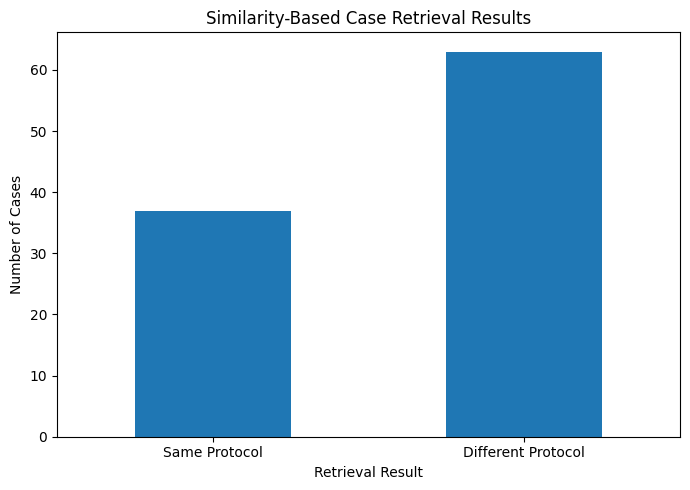

In [30]:
retrieval_data = pd.Series({
    "Same Protocol": correct_retrievals,
    "Different Protocol": total_cases - correct_retrievals
})

plt.figure(figsize=(7, 5))

retrieval_data.plot(kind="bar")

plt.title("Similarity-Based Case Retrieval Results")
plt.xlabel("Retrieval Result")
plt.ylabel("Number of Cases")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

## 13. Retrieval Performance by Confidence Level

This analysis examines how similarity-based retrieval performance varies across different confidence levels.

The evaluation checks whether the retrieved similar case belongs to the same protocol category as the original network fault case.

In [31]:
confidence_performance = (
    df.groupby("AI_Confidence")["Protocol_Match"]
    .mean() * 100
)

confidence_performance = confidence_performance.sort_values(
    ascending=False
)

print("Protocol Retrieval Performance by Confidence Level:")
print(confidence_performance.round(2))

Protocol Retrieval Performance by Confidence Level:
AI_Confidence
Low       37.50
Medium    35.71
Name: Protocol_Match, dtype: float64


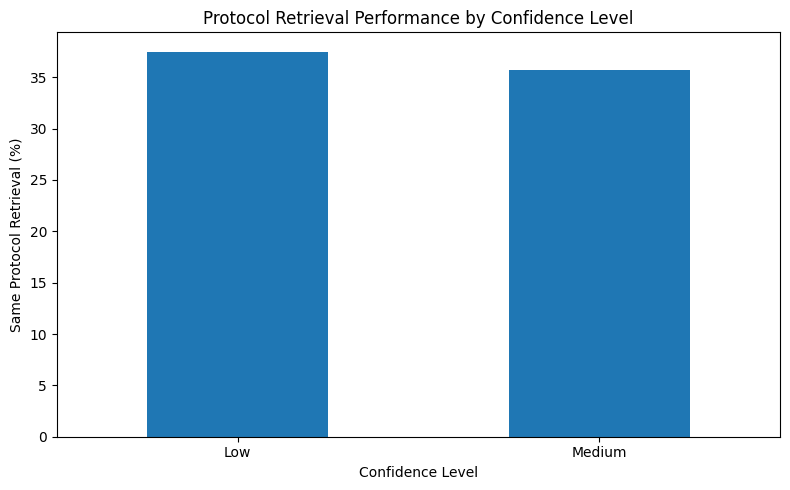

In [32]:
plt.figure(figsize=(8, 5))

confidence_performance.plot(kind="bar")

plt.title("Protocol Retrieval Performance by Confidence Level")
plt.xlabel("Confidence Level")
plt.ylabel("Same Protocol Retrieval (%)")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

## 14. Protocol-Wise Network Fault Analysis

This analysis shows the number of network fault cases associated with each protocol or technology.

It helps identify the representation of different protocols in the NetForensics AI dataset.

In [34]:
protocol_analysis = df["Category"].value_counts()

print("Network Cases by Protocol:")
print(protocol_analysis)

Network Cases by Protocol:
Category
Dynamic Routing             9
Switching                   8
Routing                     5
VLAN                        4
Ethernet                    4
DHCP                        3
Advanced Routing            3
Network Security            3
NAT                         3
Network Services            3
Switch Security             2
ARP                         2
IEEE 802.1Q                 2
RSTP                        2
IPv6                        2
STP                         2
UDP                         2
ICMP                        2
TCP                         2
SSH                         2
SNMP                        2
HTTPS                       2
IPv4                        2
HTTP                        2
Switching Security          1
Network Discovery           1
EtherChannel / PAgP         1
Interface Failure           1
IP Addressing               1
VLAN/Trunk                  1
DHCP Services               1
DNS/Name Resolution         1
ARP 

## 15. Similarity-Based Retrieval Performance by Protocol

This analysis evaluates how often the most similar retrieved case belongs to the same protocol category as the original case.

The results help identify protocols where the similarity-based retrieval approach performs better.

In [36]:
protocol_performance = (
    df.groupby("Category")["Protocol_Match"]
    .mean() * 100
)

protocol_performance = protocol_performance.sort_values(
    ascending=False
)

print("Protocol Retrieval Performance:")
print(protocol_performance.round(2))

Protocol Retrieval Performance:
Category
Advanced Routing            100.00
UDP                         100.00
Network Services            100.00
SSH                         100.00
SNMP                        100.00
VLAN                         75.00
NAT                          66.67
Dynamic Routing              55.56
HTTPS                        50.00
HTTP                         50.00
TCP                          50.00
IEEE 802.1Q                  50.00
RSTP                         50.00
Ethernet                     50.00
ARP                          50.00
Switch Security              50.00
Switching                    50.00
DHCP                         33.33
Routing                      20.00
ICMP                          0.00
First Hop Redundancy          0.00
Ethernet / Duplex             0.00
FTP                           0.00
EtherChannel / PAgP           0.00
DNS/Name Resolution           0.00
EIGRP                         0.00
EtherChannel                  0.00
CDP / Neighbor

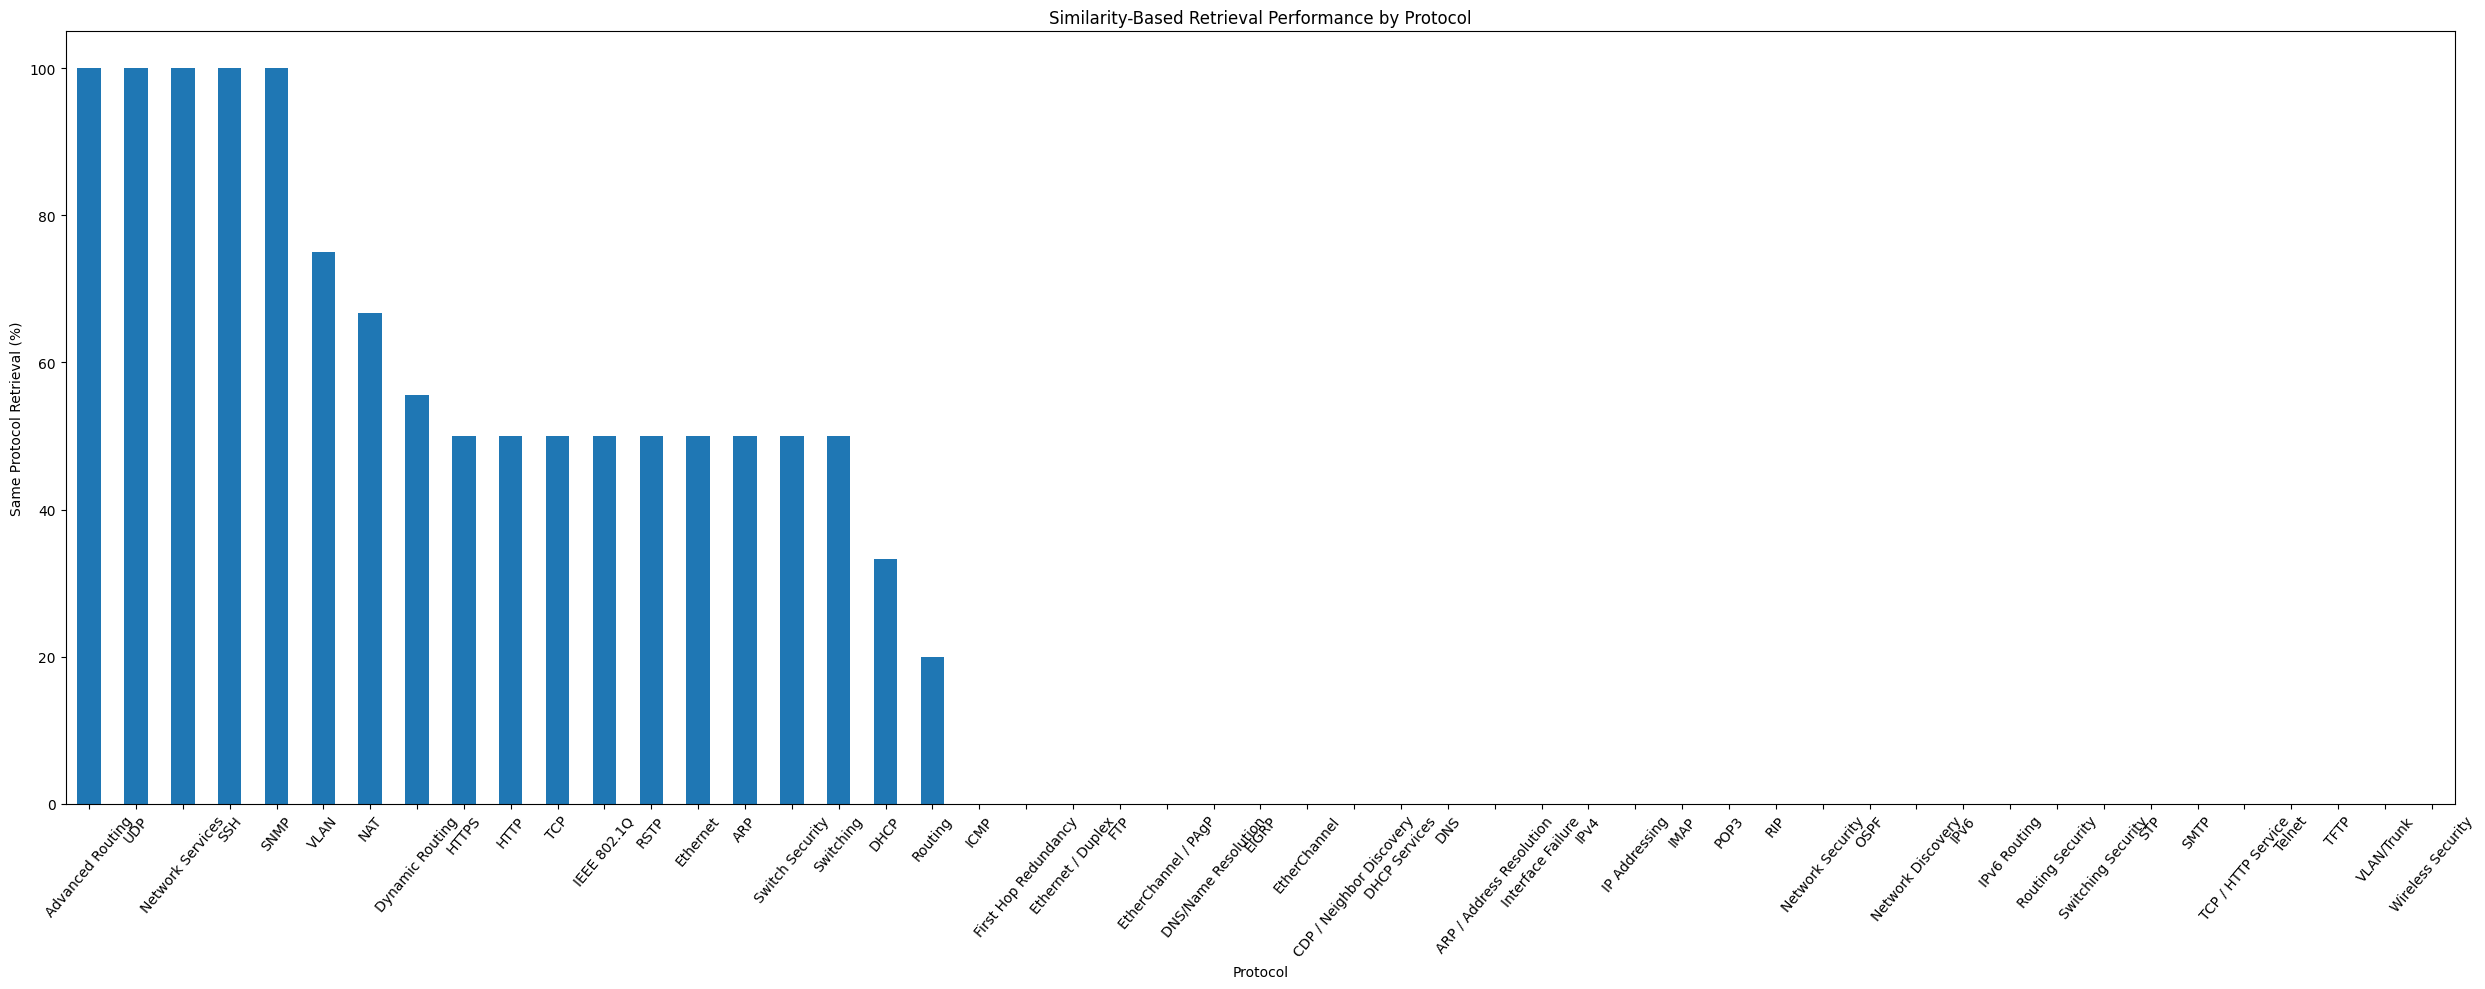

In [40]:
plt.figure(figsize=(25, 10))

protocol_performance.plot(kind="bar")

plt.title("Similarity-Based Retrieval Performance by Protocol")
plt.xlabel("Protocol")
plt.ylabel("Same Protocol Retrieval (%)")

plt.xticks(rotation=50)
plt.tight_layout()

plt.show()

## 16. Final Project Dataset Summary

This section provides a summary of the final NetForensics AI dataset and similarity-based retrieval results.

The summary includes:

- Total network fault cases.
- Number of unique protocols.
- OSI layer distribution.
- Severity distribution.
- AI confidence distribution.
- Human review priority.
- Protocol retrieval performance.

In [42]:
print("=" * 55)
print("NETFORENSICS AI - FINAL PROJECT SUMMARY")
print("=" * 55)

print("\nTotal Network Fault Cases:", len(df))
print("Unique Protocols:", df["Category"].nunique())

print("\nOSI Layer Distribution:")
print(df["OSI_Layer"].value_counts())

print("\nSeverity Distribution:")
print(df["Severity"].value_counts())

print("\nAI Confidence Distribution:")
print(df["AI_Confidence"].value_counts())

print("\nHuman Review Priority:")
print(df["Human_Review_Priority"].value_counts())

print("\nProtocol Retrieval Accuracy:",
      round(retrieval_accuracy, 2), "%")

print("=" * 55)

NETFORENSICS AI - FINAL PROJECT SUMMARY

Total Network Fault Cases: 100
Unique Protocols: 51

OSI Layer Distribution:
OSI_Layer
Layer 3      38
Layer 2      29
Layer 7      19
Layer 4       4
Layer 1–2     3
Layer 1       2
Layer 2–3     2
Layer 2/3     1
Layer 4/7     1
Layer 3/4     1
Name: count, dtype: int64

Severity Distribution:
Severity
High        51
Medium      27
Low         20
Critical     2
Name: count, dtype: int64

AI Confidence Distribution:
AI_Confidence
Low       72
Medium    28
Name: count, dtype: int64

Human Review Priority:
Human_Review_Priority
High Priority      72
Medium Priority    28
Name: count, dtype: int64

Protocol Retrieval Accuracy: 37.0 %


## 17. Key Findings

The following findings are generated from the final analysis of the NetForensics AI dataset and the similarity-based case retrieval system.

In [44]:
most_common_protocol = df["Category"].value_counts().idxmax()
most_common_severity = df["Severity"].value_counts().idxmax()
most_common_confidence = df["AI_Confidence"].value_counts().idxmax()

highest_protocol = protocol_performance.idxmax()
highest_protocol_score = protocol_performance.max()

print("KEY FINDINGS")
print("-" * 45)

print("Most represented protocol:", most_common_protocol)

print("Most common severity level:", most_common_severity)

print("Most common AI confidence level:", most_common_confidence)

print(
    "Overall protocol retrieval accuracy:",
    round(retrieval_accuracy, 2),
    "%"
)

print(
    "Best performing protocol:",
    highest_protocol,
    "-",
    round(highest_protocol_score, 2),
    "%"
)

KEY FINDINGS
---------------------------------------------
Most represented protocol: Dynamic Routing
Most common severity level: High
Most common AI confidence level: Low
Overall protocol retrieval accuracy: 37.0 %
Best performing protocol: Advanced Routing - 100.0 %


## 18. Interpretation of Results

The NetForensics AI system uses TF-IDF vectorization and cosine similarity to retrieve historical network fault cases with similar symptoms and evidence.

The evaluation focuses on protocol-level retrieval performance because the system is designed as a case-based recommendation approach rather than a direct fault classification model.

A higher similarity score indicates a stronger textual relationship between the current network fault case and a historical troubleshooting case.

The confidence level provides an additional indicator of how strongly a case matches available historical data.

Cases with lower confidence are assigned higher priority for human review, ensuring that automated recommendations are not blindly accepted.

## 19. Final NetForensics AI System Workflow

The complete NetForensics AI system follows a multi-stage network troubleshooting workflow.

Network Fault Case
        │
        ▼
Dataset Preparation and Validation
        │
        ▼
Rule-Based Fault Detection
        │
        ▼
Symptom and Evidence Analysis
        │
        ▼
TF-IDF Text Vectorization
        │
        ▼
Cosine Similarity Calculation
        │
        ▼
Historical Case Retrieval
        │
        ▼
AI-Assisted Troubleshooting Recommendation
        │
        ▼
Confidence Estimation
        │
        ▼
Human Review Decision
        │
        ├──────────────────────┐
        ▼                      ▼
 High Confidence        Medium / Low Confidence
        │                      │
        ▼                      ▼
 Automated Assistance      Human Verification
        │                      │
        └───────────┬──────────┘
                    ▼
       Final Troubleshooting Decision

# 20. Final Project Conclusion

NetForensics AI was developed as an intelligent network fault detection and troubleshooting support system.

The project uses a structured dataset containing network protocols, symptoms, evidence, expected faults, severity levels, troubleshooting commands, and suggested fixes.

The project was implemented in multiple phases. Initially, the dataset was prepared and validated. Rule-based detection was then used to identify possible network faults based on structured troubleshooting information.

A similarity-based AI-assisted approach was implemented using TF-IDF vectorization and cosine similarity. Instead of directly classifying a fault, the system retrieves the most similar historical network troubleshooting case based on available symptoms and evidence.

The retrieved case is used to provide a probable fault, recommended troubleshooting command, and suggested fix. Confidence levels are generated from similarity scores to indicate the strength of the retrieved match.

A human-in-the-loop mechanism was included to ensure that uncertain recommendations receive additional verification. Medium and low confidence cases are prioritized for human review.

The final analysis evaluated protocol-level case retrieval performance, confidence distributions, human review priorities, and network fault distributions.

The project demonstrates how rule-based reasoning and similarity-based AI techniques can work together to support network troubleshooting. The system is designed as an assistive tool and does not replace human network administrators.

Overall, NetForensics AI provides an explainable and structured approach for retrieving relevant historical network fault cases and supporting troubleshooting decisions.

## Project Completion Summary

The NetForensics AI project was completed through the following phases:

1. Dataset Preparation and Validation
2. Rule-Based Network Fault Detection
3. Similarity-Based AI-Assisted Diagnosis
4. Human Review and Responsible AI
5. Visualization and Final Analysis

The final system combines structured network troubleshooting data, rule-based detection, TF-IDF vectorization, cosine similarity, confidence estimation, and human review.

This creates an explainable AI-assisted framework for network fault analysis and troubleshooting support.